# Klasifikasi Tutupan Lahan 6 Kelas Menggunakan Sentinel-2 dan Random Forest

Notebook baru ini mengadaptasi alur notebook klasifikasi sawah/non-sawah: membaca shapefile sampel, mengunduh citra Sentinel-2 sebagai GeoTIFF melalui openEO, mengekstrak nilai raster dengan Rasterio, menghitung indeks spektral, melatih Random Forest, lalu menyimpan peta klasifikasi GeoTIFF.

**Kelas:** sawah, bangunan, danau, laut, hutan, mangrove.

**Sampel yang tersedia:** 291 polygon (sawah 50, bangunan 50, danau 31, laut 60, hutan 50, mangrove 50).

> Catatan: notebook ini mengunduh raster per cluster agar extent tidak terlalu besar. Jika `create_job()` atau `download()` tetap menghasilkan `503 no available server`, itu adalah respons layanan openEO; kode lokal tidak dapat memperbaiki gangguan server. Tunggu lalu jalankan ulang hanya sel unduhan yang gagal.


## 1. Instalasi library

Jalankan sekali jika library belum tersedia. Jika sudah terpasang, lewati sel ini.

## 2. Import library dan buat folder keluaran

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from rasterio.warp import calculate_default_transform, reproject, Resampling
from sklearn.cluster import DBSCAN
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

os.makedirs("materi", exist_ok=True)
os.makedirs("materi/raster_cluster", exist_ok=True)
os.makedirs("materi/hasil", exist_ok=True)
os.makedirs("materi/dataset", exist_ok=True)

print("Folder keluaran siap.")


Folder keluaran siap.


## 3. Baca enam shapefile dan beri label

Pastikan struktur folder dan nama file sesuai. Jika lokasi file berbeda, ubah `base_paths`.

In [2]:
import os
import geopandas as gpd
import pandas as pd
import numpy as np

base_paths = {
    "sawah": "Sampel Sawah/input.shp",
    "bangunan": "Sampel Non-sawah/input.shp",
    "danau": "Danau/input.shp",
    "laut": "laut_lepas/input.shp",
    "hutan": "lahan hijau/input.shp",
    "mangrove": "mangrove/input.shp",
}

def cari_path(rel_p):
    for prefix in ["materi", "materi/materi", "materi/sampel", ".", "..", "../materi"]:
        full = os.path.normpath(os.path.join(prefix, rel_p))
        if os.path.exists(full):
            return full
        # coba lowercase
        full_lower = os.path.normpath(os.path.join(prefix, rel_p.lower()))
        if os.path.exists(full_lower):
            return full_lower
    return rel_p

frames = []
for label, rel in base_paths.items():
    p = cari_path(rel)
    if not os.path.exists(p):
        # Coba nama label langsung
        p = cari_path(f"{label}/input.shp")
    if not os.path.exists(p):
        raise FileNotFoundError(f"File tidak ditemukan: {rel}")
    gdf = gpd.read_file(p)
    if gdf.crs is None:
        raise ValueError(f"CRS belum tersedia pada {p}")
    gdf = gdf[["geometry"]].copy()
    gdf["label"] = label
    frames.append(gdf)
    print(f"{label}: {len(gdf)}")

samples = gpd.GeoDataFrame(
    pd.concat(frames, ignore_index=True),
    geometry="geometry",
    crs=frames[0].crs
)
samples = samples[samples.geometry.notna() & ~samples.geometry.is_empty].copy()
samples["geometry"] = samples.geometry.make_valid()
samples = samples.reset_index(drop=True)
samples["sample_id"] = np.arange(1, len(samples) + 1)

print("\nTotal sampel:", len(samples))
print(samples["label"].value_counts())
display(samples.head())


sawah: 50
bangunan: 50
danau: 31
laut: 60


hutan: 50
mangrove: 50

Total sampel: 291
label
laut        60
sawah       50
bangunan    50
hutan       50
mangrove    50
danau       31
Name: count, dtype: int64


,geometry,label,sample_id
0,"MULTIPOLYGON (((112.19475 -7.20458, 112.19475 ...",sawah,1
1,"POLYGON ((112.19487 -7.20461, 112.19532 -7.204...",sawah,2
2,"POLYGON ((112.19536 -7.20448, 112.1955 -7.2044...",sawah,3
3,"POLYGON ((112.19532 -7.20468, 112.19548 -7.204...",sawah,4
4,"POLYGON ((112.194 -7.20475, 112.1947 -7.20487,...",sawah,5


## 4. Samakan CRS dan buat cluster lokasi

DBSCAN menggunakan centroid dalam CRS UTM agar jarak dihitung dalam meter. `eps=20000` membentuk cluster berdasarkan kedekatan 20 km. Cluster diproses satu per satu agar tidak mengunduh satu raster besar yang meliputi lokasi berjauhan.

In [3]:
samples_utm = samples.to_crs("EPSG:32749")
centroids = samples_utm.geometry.centroid
coords = np.column_stack([centroids.x.to_numpy(), centroids.y.to_numpy()])

samples["cluster"] = DBSCAN(eps=20000, min_samples=1).fit_predict(coords) + 1

print("Jumlah sampel:", len(samples))
print("Jumlah cluster:", samples["cluster"].nunique())
display(samples.groupby(["cluster", "label"]).size().unstack(fill_value=0))


Jumlah sampel: 291
Jumlah cluster: 3


label,bangunan,danau,hutan,laut,mangrove,sawah
cluster,,,,,,
1,50,31,0,60,44,50
2,0,0,50,0,0,0
3,0,0,0,0,6,0


## 5. Hubungkan ke OpenEO Copernicus

Jalankan autentikasi bila diminta browser. Jika koneksi sudah ada dalam sesi, sel ini boleh dijalankan ulang.

In [4]:
import glob, os

clusters_ready = bool(glob.glob("materi/tif_10_band/cluster_*/*.tif") or glob.glob("tif_10_band/cluster_*/*.tif"))
connection = None

if not clusters_ready:
    print("Mencoba menghubungkan ke OpenEO Copernicus...")
    try:
        import openeo
        connection = openeo.connect("https://openeo.dataspace.copernicus.eu")
        connection.authenticate_oidc()
        print("Koneksi OpenEO siap.")
    except Exception as e:
        print(f"Catatan OpenEO: {e}")
        print("Melanjutkan dengan data lokal yang telah tersedia.")
else:
    print("Raster cluster sudah tersedia di folder tif_10_band/. Melewati unduhan online OpenEO.")
    print("Jika ingin mengunduh ulang via OpenEO, hubungkan dengan: connection = openeo.connect(...); connection.authenticate_oidc()")


Raster cluster sudah tersedia di folder tif_10_band/. Melewati unduhan online OpenEO.
Jika ingin mengunduh ulang via OpenEO, hubungkan dengan: connection = openeo.connect(...); connection.authenticate_oidc()


## 6. Unduh raster Sentinel-2 per cluster sebagai GeoTIFF

Raster berisi 10 band. Indeks spektral dihitung secara lokal setelah unduhan. Periode default di bawah adalah 31 Agustus 2025 sampai 31 Agustus 2026; ubah jika instruksi tugas menentukan periode lain.

**Jika server membalas `503 no available server`, hentikan pengulangan.** Katalog yang bisa diakses tidak menjamin backend pemrosesan batch sedang tersedia. Coba lagi nanti. Kode ini hanya menyimpan file jika unduhan berhasil.

In [5]:
import os

if connection is not None:
    try:
        uji_sampel = samples.iloc[[0]].to_crs("EPSG:4326")
        west, south, east, north = uji_sampel.total_bounds
        cube_uji = connection.load_collection(
            "SENTINEL2_L2A",
            spatial_extent={"west": float(west), "south": float(south), "east": float(east), "north": float(north), "crs": "EPSG:4326"},
            temporal_extent=["2025-08-31", "2025-09-30"],
            bands=["B04"],
            max_cloud_cover=50
        )
        cube_uji = cube_uji.reduce_dimension(dimension="t", reducer="median")
        os.makedirs("materi/ujicoba", exist_ok=True)
        cube_uji.download("materi/ujicoba/uji_B04.tif", format="GTiff")
        print("Unduhan uji berhasil.")
    except Exception as e:
        print(f"Uji unduh dilewati: {e}")
else:
    print("OpenEO tidak terhubung; melewati uji unduh online.")


OpenEO tidak terhubung; melewati uji unduh online.


In [6]:
import os
import openeo

if connection is not None:
    try:
        os.makedirs("materi/ujicoba", exist_ok=True)
        bands = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]
        cube_10band = connection.load_collection(
            "SENTINEL2_L2A",
            spatial_extent={"west": float(west), "south": float(south), "east": float(east), "north": float(north), "crs": "EPSG:4326"},
            temporal_extent=["2025-08-31", "2025-09-30"],
            bands=bands,
            max_cloud_cover=50
        )
        cube_10band = cube_10band.reduce_dimension(dimension="t", reducer="median").save_result(format="GTiff")
        job = cube_10band.create_job(title="Uji Sentinel-2 10 Band")
        print("Job ID:", job.job_id)
        job.start_and_wait()
        job.get_results().download_files("materi/ujicoba")
        print("Unduhan 10 band selesai.")
    except Exception as e:
        print(f"Uji unduh 10 band dilewati: {e}")
else:
    print("OpenEO tidak terhubung; melewati uji batch online.")


OpenEO tidak terhubung; melewati uji batch online.


In [7]:

# Mengubah seluruh sampel ke koordinat geografis
samples_wgs84 = samples.to_crs("EPSG:4326")

# Mengambil batas seluruh sampel
west, south, east, north = samples_wgs84.total_bounds

# Batas area untuk openEO
spatial_extent = {
    "west": float(west),
    "south": float(south),
    "east": float(east),
    "north": float(north)
}

print("Batas area unduhan:")
print(spatial_extent)


Batas area unduhan:
{'west': 112.0092144, 'south': -7.6605757, 'east': 113.4477865, 'north': -6.8333574}


In [8]:
# ====== DEFINISI VARIABEL GLOBAL YANG DIPAKAI DI SEL BERIKUTNYA ======
BANDS = [
    "B02", "B03", "B04", "B05", "B06",
    "B07", "B08", "B8A", "B11", "B12"
]
eps = 1e-10

# Pastikan samples dan cluster sudah tersedia
if "samples" not in locals():
    raise NameError("Jalankan sel 5 dan sel 7 terlebih dahulu untuk memuat data samples.")

# Cari raster hasil download per cluster
RASTER_PATHS = {}

for cluster_id in sorted(samples["cluster"].unique()):
    candidate_dirs = [
        os.path.join("materi", "tif_10_band", f"cluster_{cluster_id}"),
        os.path.join("tif_10_band", f"cluster_{cluster_id}"),
        os.path.join("materi", "sentinel"),
    ]
    rasters = []
    for c_dir in candidate_dirs:
        if os.path.exists(c_dir):
            for root, _, files in os.walk(c_dir):
                for f in files:
                    if f.lower().endswith((".tif", ".tiff")):
                        rasters.append(os.path.join(root, f))
        if rasters:
            break

    if rasters:
        RASTER_PATHS[int(cluster_id)] = sorted(rasters)[0]
        print(f"Cluster {cluster_id}: {RASTER_PATHS[int(cluster_id)]}")
    else:
        print(f"Cluster {cluster_id}: raster tidak ditemukan.")

print("RASTER_PATHS:", RASTER_PATHS)


Cluster 1: materi\tif_10_band\cluster_1\cluster_1.tif
Cluster 2: materi\tif_10_band\cluster_2\cluster_2.tif
Cluster 3: materi\tif_10_band\cluster_3\cluster_3.tif
RASTER_PATHS: {1: 'materi\\tif_10_band\\cluster_1\\cluster_1.tif', 2: 'materi\\tif_10_band\\cluster_2\\cluster_2.tif', 3: 'materi\\tif_10_band\\cluster_3\\cluster_3.tif'}


## 7. Periksa raster yang berhasil diunduh

Nama band GeoTIFF tidak selalu tersimpan sebagai deskripsi band. Notebook memakai urutan `BANDS` sebagai urutan band yang diminta.

In [9]:

import os

for folder in ["materi", "ujicoba"]:
    if os.path.exists(folder):
        print(f"\nFile raster di folder {folder}:")
        for root, dirs, files in os.walk(folder):
            for file in files:
                if file.lower().endswith((".tif", ".tiff")):
                    print(os.path.join(root, file))



File raster di folder materi:
materi\hasil_klasifikasi_sawah.tif
materi\sentinel2_kedungpring.tif
materi\Sentinel2_kedungpring_sampel.tif
materi\Sentinel2_multikelas.tif
materi\materi\hasil_klasifikasi_sawah.tif
materi\materi\sentinel2_kedungpring.tif
materi\materi\Sentinel2_kedungpring_sampel.tif
materi\materi\ujicoba\openEO.tif
materi\sentinel\zona_danau.tif
materi\sentinel\zona_lahan_hijau.tif
materi\sentinel\zona_laut.tif
materi\sentinel\zona_mangrove.tif
materi\sentinel\zona_sawah_bangunan.tif
materi\tif_10_band\cluster_1\cluster_1.tif
materi\tif_10_band\cluster_2\cluster_2.tif
materi\tif_10_band\cluster_3\cluster_3.tif
materi\ujicoba\openEO.tif
materi\ujicoba\uji_B04.tif


In [10]:

import os
import rasterio

daftar_raster = [
    r"materi\hasil_klasifikasi_sawah.tif",
    r"materi\sentinel2_kedungpring.tif",
    r"materi\Sentinel2_kedungpring_sampel.tif",
    r"materi\ujicoba\openEO.tif"
]

for path in daftar_raster:
    if os.path.exists(path):
        print("\n" + "=" * 50)
        print("File:", path)

        with rasterio.open(path) as src:
            print("Jumlah band :", src.count)
            print("Ukuran      :", src.width, "x", src.height)
            print("CRS         :", src.crs)
            print("Batas area  :", src.bounds)
            print("NoData      :", src.nodata)
            print("Deskripsi   :", src.descriptions)
    else:
        print("\nFile tidak ditemukan:", path)



File: materi\hasil_klasifikasi_sawah.tif
Jumlah band : 1
Ukuran      : 84 x 225
CRS         : EPSG:32749
Batas area  : BoundingBox(left=631170.0, bottom=9201450.0, right=632010.0, top=9203700.0)
NoData      : 0.0
Deskripsi   : (None,)

File: materi\sentinel2_kedungpring.tif
Jumlah band : 5
Ukuran      : 2214 x 1666
CRS         : EPSG:32749
Batas area  : BoundingBox(left=621450.0, bottom=9203930.0, right=643590.0, top=9220590.0)
NoData      : -32768.0
Deskripsi   : ('B02', 'B03', 'B04', 'B08', 'B11')

File: materi\Sentinel2_kedungpring_sampel.tif


Jumlah band : 5
Ukuran      : 84 x 225
CRS         : EPSG:32749
Batas area  : BoundingBox(left=631170.0, bottom=9201450.0, right=632010.0, top=9203700.0)
NoData      : -32768.0
Deskripsi   : ('B02', 'B03', 'B04', 'B08', 'B11')

File: materi\ujicoba\openEO.tif
Jumlah band : 10
Ukuran      : 7 x 4
CRS         : EPSG:32749
Batas area  : BoundingBox(left=631910.0, bottom=9203460.0, right=631980.0, top=9203500.0)
NoData      : -32768.0
Deskripsi   : ('B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B11', 'B12')


In [11]:


# Cek batas seluruh 291 sampel
samples_utm = samples.to_crs("EPSG:32749")

print("Jumlah sampel:", len(samples_utm))
print("Batas seluruh sampel:")
print(samples_utm.total_bounds)


Jumlah sampel: 291
Batas seluruh sampel:
[ 611512.83221165 9152505.1847546   770221.62115094 9244555.72284482]


In [12]:
import rasterio
import os

raster_path = "materi/ujicoba/openEO.tif"
if not os.path.exists(raster_path):
    raster_path = "ujicoba/openEO.tif"

if os.path.exists(raster_path):
    with rasterio.open(raster_path) as src:
        print("Jumlah band:", src.count)
        print("Nama/indeks band:", src.indexes)
        print("Ukuran raster:", src.width, "x", src.height)
        print("CRS:", src.crs)
        print("Batas raster:", src.bounds)
        print("NoData:", src.nodata)
else:
    print("Raster uji coba openEO.tif tidak ditemukan.")


Jumlah band:

 10
Nama/indeks band: (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)
Ukuran raster: 7 x 4
CRS: EPSG:32749
Batas raster: BoundingBox(left=631910.0, bottom=9203460.0, right=631980.0, top=9203500.0)
NoData: -32768.0


## 8. Ekstrak nilai band pada setiap polygon

Setiap polygon memperoleh rata-rata nilai piksel di dalam polygon untuk masing-masing dari 10 band. Sampel di luar raster atau tanpa piksel valid akan dilewati dan dicatat.

In [13]:
band_names = BANDS
records = []
skipped = []

for cluster_id, path in RASTER_PATHS.items():
    if not os.path.exists(path):
        print(f"Lewati cluster {cluster_id}: raster tidak tersedia.")
        continue

    group = samples[samples["cluster"] == cluster_id].to_crs("EPSG:32749")

    with rasterio.open(path) as src:
        for _, row in group.iterrows():
            try:
                data, _ = mask(src, [row.geometry], crop=True, filled=False)
                values = []
                for band_idx in range(data.shape[0]):
                    band = data[band_idx]
                    valid = band.compressed()
                    if src.nodata is not None:
                        valid = valid[valid != src.nodata]
                    valid = valid[np.isfinite(valid)]
                    values.append(float(valid.mean()) if valid.size else np.nan)

                if np.all(np.isnan(values)):
                    skipped.append((row["sample_id"], row["label"], "tidak ada piksel valid"))
                    continue

                record = {
                    "sample_id": int(row["sample_id"]),
                    "label": row["label"],
                    "cluster": int(cluster_id)
                }
                record.update(dict(zip(band_names, values)))
                records.append(record)

            except Exception as e:
                skipped.append((row["sample_id"], row["label"], str(e)))

df = pd.DataFrame(records)
print("Sampel berhasil diekstrak:", len(df))
print("Sampel dilewati:", len(skipped))
if skipped:
    display(pd.DataFrame(skipped, columns=["sample_id", "label", "alasan"]).head(20))
display(df.head())


Sampel berhasil diekstrak: 214
Sampel dilewati: 77


,sample_id,label,alasan
0,1,sawah,tidak ada piksel valid
1,2,sawah,tidak ada piksel valid
2,3,sawah,tidak ada piksel valid
3,9,sawah,tidak ada piksel valid
4,10,sawah,tidak ada piksel valid
5,11,sawah,tidak ada piksel valid
6,12,sawah,tidak ada piksel valid
7,14,sawah,tidak ada piksel valid
8,15,sawah,tidak ada piksel valid
9,16,sawah,tidak ada piksel valid


,sample_id,label,cluster,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12
0,4,sawah,1,1234.0,1320.0,1127.0,1576.0,2026.0,2512.0,2634.0,2502.0,1366.0,880.0
1,5,sawah,1,1195.0,1301.0,1272.0,1621.0,2147.0,2472.0,2480.0,2851.0,1376.0,951.0
2,6,sawah,1,1181.0,1360.0,1277.0,1506.0,2228.0,2352.0,2551.0,2698.0,1526.0,965.0
3,7,sawah,1,1156.0,1352.5,1194.5,1669.5,2152.0,2381.0,2469.0,2743.5,1501.0,961.5
4,8,sawah,1,1142.0,1297.0,1253.0,1573.0,2010.0,2396.0,2681.0,2546.0,1361.0,960.0


## 9. Hitung lima indeks spektral

Formula memakai nilai band Sentinel-2 yang sudah diekstrak. `1e-10` mencegah pembagian dengan nol.

In [14]:
eps = 1e-10

df["NDVI"] = (df["B08"] - df["B04"]) / (df["B08"] + df["B04"] + eps)
df["NDWI"] = (df["B03"] - df["B08"]) / (df["B03"] + df["B08"] + eps)
df["NDBI"] = (df["B11"] - df["B08"]) / (df["B11"] + df["B08"] + eps)
df["NDMI"] = (df["B08"] - df["B11"]) / (df["B08"] + df["B11"] + eps)
df["MNDWI"] = (df["B03"] - df["B11"]) / (df["B03"] + df["B11"] + eps)

feature_cols = BANDS + ["NDVI", "NDWI", "NDBI", "NDMI", "MNDWI"]

# Buang baris yang tidak memiliki nilai fitur lengkap
df_model = df.dropna(subset=feature_cols + ["label"]).copy()

print("Jumlah data siap model:", len(df_model))
print("\nDistribusi kelas:")
print(df_model["label"].value_counts())
display(df_model.head())


Jumlah data siap model: 214

Distribusi kelas:
label
laut        60
hutan       50
mangrove    47
danau       30
sawah       19
bangunan     8
Name: count, dtype: int64


,sample_id,label,cluster,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12,NDVI,NDWI,NDBI,NDMI,MNDWI
0,4,sawah,1,1234.0,1320.0,1127.0,1576.0,2026.0,2512.0,2634.0,2502.0,1366.0,880.0,0.400691,-0.332322,-0.317000,0.317000,-0.017126
1,5,sawah,1,1195.0,1301.0,1272.0,1621.0,2147.0,2472.0,2480.0,2851.0,1376.0,951.0,0.321962,-0.311822,-0.286307,0.286307,-0.028016
2,6,sawah,1,1181.0,1360.0,1277.0,1506.0,2228.0,2352.0,2551.0,2698.0,1526.0,965.0,0.332811,-0.304526,-0.251410,0.251410,-0.057519
3,7,sawah,1,1156.0,1352.5,1194.5,1669.5,2152.0,2381.0,2469.0,2743.5,1501.0,961.5,0.347891,-0.292163,-0.243829,0.243829,-0.052041
4,8,sawah,1,1142.0,1297.0,1253.0,1573.0,2010.0,2396.0,2681.0,2546.0,1361.0,960.0,0.362989,-0.347914,-0.326571,0.326571,-0.024078


## 10. Simpan dataset fitur

In [15]:
csv_path = "materi/dataset/dataset_fitur_6_kelas.csv"
df_model.to_csv(csv_path, index=False)
print("Dataset tersimpan:", csv_path)


Dataset tersimpan: materi/dataset/dataset_fitur_6_kelas.csv


## 11. Bagi data training dan testing

Stratifikasi menjaga proporsi kelas pada train dan test. Jika suatu kelas hanya memiliki satu sampel valid setelah ekstraksi, pembagian stratified tidak dapat dilakukan; periksa kembali sampel/raster kelas tersebut.

In [16]:
X = df_model[feature_cols]
y = df_model["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))


Training:

 171
Testing: 43


## 12. Latih Random Forest dan evaluasi

In [17]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Akurasi:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Akurasi: 1.0

Classification report:
              precision    recall  f1-score   support

    bangunan       1.00      1.00      1.00         2
       danau       1.00      1.00      1.00         6
       hutan       1.00      1.00      1.00        10
        laut       1.00      1.00      1.00        12
    mangrove       1.00      1.00      1.00         9
       sawah       1.00      1.00      1.00         4

    accuracy                           1.00        43
   macro avg       1.00      1.00      1.00        43
weighted avg       1.00      1.00      1.00        43



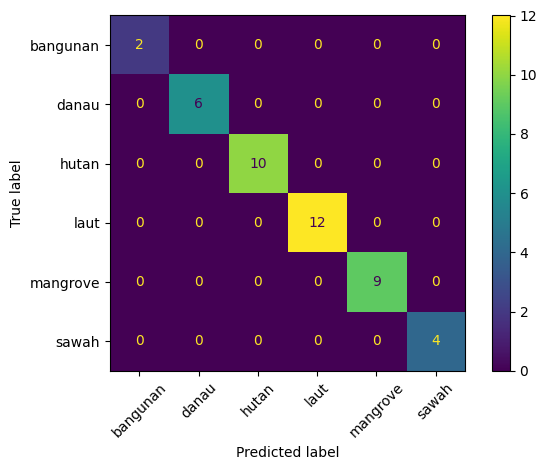

In [18]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()


## 13. Klasifikasikan setiap raster cluster dan simpan GeoTIFF

Setiap raster keluaran mempertahankan transformasi, CRS, dan dimensi raster asal. Kode membentuk indeks spektral per piksel dan menggunakan urutan fitur yang sama seperti saat model dilatih.

Kode kelas: 0 = NoData, 1 = bangunan, 2 = danau, 3 = hutan, 4 = laut, 5 = mangrove, 6 = sawah.

In [19]:
class_order = ["bangunan", "danau", "hutan", "laut", "mangrove", "sawah"]
class_to_code = {name: i + 1 for i, name in enumerate(class_order)}
code_to_class = {v: k for k, v in class_to_code.items()}
print("Kode kelas:", class_to_code)

for cluster_id, path in RASTER_PATHS.items():
    if not os.path.exists(path):
        print(f"Lewati cluster {cluster_id}: raster tidak tersedia.")
        continue

    output_class = f"materi/hasil/hasil_klasifikasi_cluster_{cluster_id}.tif"

    with rasterio.open(path) as src:
        raster = src.read().astype("float32")
        profile = src.profile.copy()
        nodata = src.nodata

        # Semua band harus valid untuk klasifikasi
        pixel_valid = np.all(np.isfinite(raster), axis=0)
        if nodata is not None:
            pixel_valid &= np.all(raster != nodata, axis=0)

        band_index = {name: i for i, name in enumerate(BANDS)}
        b03 = raster[band_index["B03"]]
        b04 = raster[band_index["B04"]]
        b08 = raster[band_index["B08"]]
        b11 = raster[band_index["B11"]]

        ndvi = (b08 - b04) / (b08 + b04 + eps)
        ndwi = (b03 - b08) / (b03 + b08 + eps)
        ndbi = (b11 - b08) / (b11 + b08 + eps)
        ndmi = (b08 - b11) / (b08 + b11 + eps)
        mndwi = (b03 - b11) / (b03 + b11 + eps)

        layers = [raster[band_index[b]] for b in BANDS] + [
            ndvi, ndwi, ndbi, ndmi, mndwi
        ]
        pixel_matrix = np.stack(layers, axis=-1)
        flat = pixel_matrix.reshape(-1, len(feature_cols))
        valid_flat = pixel_valid.reshape(-1)

        output_flat = np.zeros(flat.shape[0], dtype=np.uint8)
        valid_idx = np.where(valid_flat)[0]
        if len(valid_idx) > 0:
            batch_size = 200000
            for start in range(0, len(valid_idx), batch_size):
                end = start + batch_size
                b_idx = valid_idx[start:end]
                predicted = model.predict(flat[b_idx])
                output_flat[b_idx] = np.array(
                    [class_to_code[p] for p in predicted],
                    dtype=np.uint8
                )

        output_array = output_flat.reshape(src.height, src.width)

        profile.update(
            count=1,
            dtype="uint8",
            nodata=0,
            compress="lzw"
        )

        with rasterio.open(output_class, "w", **profile) as dst:
            dst.write(output_array, 1)

    print("Peta klasifikasi tersimpan:", output_class)


Kode kelas: {'bangunan': 1, 'danau': 2, 'hutan': 3, 'laut': 4, 'mangrove': 5, 'sawah': 6}


E:\Document\PSD\.venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


E:\Document\PSD\.venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


E:\Document\PSD\.venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


E:\Document\PSD\.venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


...

E:\Document\PSD\.venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


E:\Document\PSD\.venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


E:\Document\PSD\.venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


E:\Document\PSD\.venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Peta klasifikasi tersimpan: materi/hasil/hasil_klasifikasi_cluster_3.tif


## 14. Simpan legenda kelas dan periksa hasil

In [20]:
legend_path = "materi/hasil/legenda_kelas.csv"
pd.DataFrame([
    {"kode": code, "kelas": label}
    for label, code in class_to_code.items()
]).to_csv(legend_path, index=False)

print("Legenda:", legend_path)

for cluster_id in RASTER_PATHS:
    out = f"materi/hasil/hasil_klasifikasi_cluster_{cluster_id}.tif"
    if os.path.exists(out):
        with rasterio.open(out) as src:
            arr = src.read(1)
            vals, counts = np.unique(arr, return_counts=True)
            print(f"\nCluster {cluster_id}: {out}")
            print(dict(zip(vals.tolist(), counts.tolist())))


Legenda: materi/hasil/legenda_kelas.csv



Cluster 1: materi/hasil/hasil_klasifikasi_cluster_1.tif
{1: 1119, 2: 2485, 3: 84, 4: 373376, 5: 1898, 6: 3831055}

Cluster 2: materi/hasil/hasil_klasifikasi_cluster_2.tif
{1: 22, 3: 2939, 5: 2, 6: 81869}

Cluster 3: materi/hasil/hasil_klasifikasi_cluster_3.tif
{1: 697, 2: 2504, 3: 82, 4: 12585, 5: 1888, 6: 2316272}


## Catatan interpretasi dan keterbatasan

1. Model hanya sebaik representasi dan kualitas sampel. Jumlah sampel aktual adalah 291, dengan distribusi kelas yang tidak seimbang.
2. Pastikan label polygon benar dan polygon mencakup lokasi yang sesuai dengan kelas tutupan lahan.
3. Periode komposit, awan, skala nilai band, dan kesesuaian tanggal sampel dapat memengaruhi hasil.
4. Output dibuat per cluster karena sampel mungkin berada di lokasi berjauhan. Jika perlu satu peta, mosaikkan raster hasil hanya jika CRS, resolusi, dan grid sesuai.
5. Jika proses unduh raster masih mendapat `503 no available server`, cek status layanan dan ulangi sel unduhan yang gagal setelah layanan pulih; jangan menjalankan seluruh notebook dari awal.
